# Bloc 5 — Données spatiales et temporelles (cours 5)
**Fichiers (Health, partie clinique)** : `clinical_encounters`, `clinical_observation`, `clinical_procedures`, `clinical_notes`, `patient_administration` (versions `_cleaned`), et `public_records/licensed_facilities` pour les coordonnées des établissements.

**Spatial**
1. Repérer les variables spatiales : des **coordonnées** (seulement les 3 établissements, dans `licensed_facilities`) et des **lieux indirects** (`home_region` des patients, `facility_license_number`), à agréger par région ou par établissement.
2. Carte des points d'intérêt (taille du point selon une variable).
3. Moran, LISA, régionalisation et Voronoï : à discuter (3 sites, 5 régions).

**Temporel**
1. Construire des séries (événements par mois ou par année).
2. Tendance, saisonnalité, cycle, bruit, et l'erreur d'interprétation à éviter.
3. Autocorrélation (ACF) et décomposition (classique et STL, `statsmodels`).
4. Anomalies par fenêtre glissante (méthodes du cours 3).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf

sns.set_style('whitegrid')
chemin = 'cleaned/'
enc = pd.read_csv(chemin + 'clinical_encounters_cleaned.csv', parse_dates=['encounter_start', 'encounter_end', 'follow_up_date'])
obs = pd.read_csv(chemin + 'clinical_observation_cleaned.csv', parse_dates=['observation_time'])
proc = pd.read_csv(chemin + 'clinical_procedures_cleaned.csv', parse_dates=['scheduled_time', 'performed_time'])
notes = pd.read_csv(chemin + 'clinical_notes_cleaned.csv', parse_dates=['document_date'])
pat = pd.read_csv(chemin + 'patient_administration_cleaned.csv', parse_dates=['date_of_birth', 'registration_date'])
fac = pd.read_csv('../public_records/licensed_facilities_cleaned.csv')

mrp = proc[proc.procedure_code == 'MRP-42']
elite = set(mrp[mrp.authorization_class == 'restricted_specialist'].patient_number)
recherche = set(mrp[mrp.authorization_class == 'research_restricted'].patient_number)
discordants = set(obs[obs.interpretation_code == 'discordant'].patient_number)

---
## Partie spatiale
### 1. Variables spatiales

In [3]:
fac[['facility_license_number', 'facility_name', 'facility_category', 'region', 'latitude', 'longitude', 'declared_services']]

,facility_license_number,facility_name,facility_category,region,latitude,longitude,declared_services
0,FAC-VLN-101,Asterion Central Clinical Campus,research_hospital,Valenne Republic,47.20,7.51,preventive medicine; cardiac assessment; clini...
1,FAC-AVL-201,Asterion Avelora Executive Clinic,private_clinic,Avelora Federation,7.35,101.62,executive health; specialist follow-up; outpat...
2,FAC-AVL-301,Threshold Earth Avelora Laboratory,research_laboratory,Avelora Federation,7.50,101.75,environmental health research; non-invasive hu...


- **Coordonnées** : seulement les 3 établissements de `licensed_facilities`, qui sont exactement les 3 `facility_license_number` des fichiers cliniques. `FAC-VLN-101` est en Valenne Republic, les deux autres en Avelora Federation, à quelques kilomètres l'un de l'autre (« Eastern Avelora Agricultural Cluster »).
- **Lieux indirects** : `home_region` (5 régions) pour les patients ; `facility_license_number` pour chaque consultation, procédure et note.

### 2. Carte des établissements (taille = nombre de consultations)

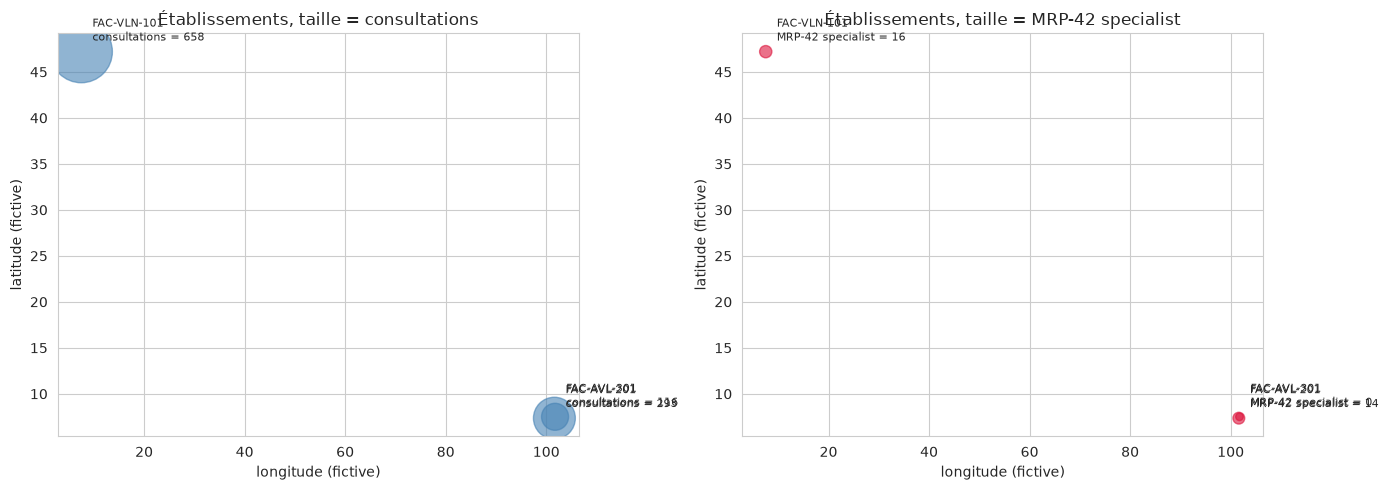

,facility_name,latitude,longitude,consultations,patients,restreintes,MRP-42,MRP-42 specialist,obs discordant,% discordant
facility_license_number,,,,,,,,,,
FAC-VLN-101,Asterion Central Clinical Campus,47.20,7.51,658,150,109,29,16.0,55,0.50
FAC-AVL-201,Asterion Avelora Executive Clinic,7.35,101.62,293,64,64,20,14.0,36,0.76
FAC-AVL-301,Threshold Earth Avelora Laboratory,7.50,101.75,116,26,18,1,0.0,18,0.90


In [4]:
act = (enc.groupby('facility_license_number')
          .agg(consultations=('encounter_number', 'size'), patients=('patient_number', 'nunique'),
               restreintes=('confidentiality_class', lambda s: (s == 'restricted').sum())))
act['MRP-42'] = mrp.groupby('performing_facility_license').size()
act['MRP-42 specialist'] = mrp[mrp.authorization_class == 'restricted_specialist'].groupby('performing_facility_license').size()
act['obs discordant'] = obs[obs.interpretation_code == 'discordant'].merge(enc[['encounter_number', 'facility_license_number']]).groupby('facility_license_number').size()
act['% discordant'] = (100 * act['obs discordant'] / obs.merge(enc[['encounter_number', 'facility_license_number']]).groupby('facility_license_number').size()).round(2)
carte = fac.set_index('facility_license_number')[['facility_name', 'latitude', 'longitude']].join(act.fillna(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, var in zip(axes, ['consultations', 'MRP-42 specialist']):
    ax.scatter(carte.longitude, carte.latitude, s=30 + 3 * carte[var], alpha=.6, color='crimson' if 'MRP' in var else 'steelblue')
    for i, r in carte.iterrows():
        ax.annotate(f'{i}\n{var} = {int(r[var])}', (r.longitude, r.latitude), textcoords='offset points', xytext=(8, 8), fontsize=8)
    ax.set_xlabel('longitude (fictive)'); ax.set_ylabel('latitude (fictive)'); ax.set_title(f'Établissements, taille = {var}')
plt.tight_layout(); plt.show()
carte

**Lecture** : `FAC-VLN-101` (Asterion Central Clinical Campus) concentre 62 % des consultations. Les 30 administrations `MRP-42 specialist` se font **uniquement** dans les deux établissements de l'Asterion Clinical Institute (`FAC-VLN-101` et `FAC-AVL-201`, la « clinique exécutive » d'Avelora), jamais au laboratoire `FAC-AVL-301`. Des observations `discordant` existent dans les 3 sites (0,5 à 0,9 % des observations) : la discordance ne vient pas d'un appareil ou d'un site particulier.

### 3. Agrégation par région de résidence

In [5]:
pat['groupe'] = np.select([pat.patient_number.isin(elite), pat.patient_number.isin(recherche)], ['MRP-42 specialist', 'MRP-42 recherche'], 'autre')
pat['discordant'] = pat.patient_number.isin(discordants)
reg = pd.crosstab(pat.home_region, pat.groupe)
reg['patients'] = pat.home_region.value_counts()
reg['discordants'] = pat.groupby('home_region').discordant.sum()
reg['% discordants'] = (100 * reg.discordants / reg.patients).round(1)
display(reg)

chi2, p, ddl, _ = stats.chi2_contingency(pd.crosstab(pat.home_region, pat.discordant))
print(f'Région × patient discordant : chi2 = {chi2:.2f}, ddl = {ddl}, p = {p:.3f}')
print('Région des 8 patients MRP-42 specialist :', pat[pat.groupe == 'MRP-42 specialist'].home_region.value_counts().to_dict())

groupe,MRP-42 recherche,MRP-42 specialist,autre,patients,discordants,% discordants
home_region,,,,,,
avelora federation,4,2,48,54,7,13.0
kintara republic,4,2,41,47,5,10.6
nordhaven union,6,1,45,52,5,9.6
tembara commonwealth,4,1,34,39,8,20.5
valenne republic,2,2,44,48,10,20.8


Région × patient discordant : chi2 = 4.34, ddl = 4, p = 0.362
Région des 8 patients MRP-42 specialist : {'kintara republic': 2, 'avelora federation': 2, 'valenne republic': 2, 'tembara commonwealth': 1, 'nordhaven union': 1}


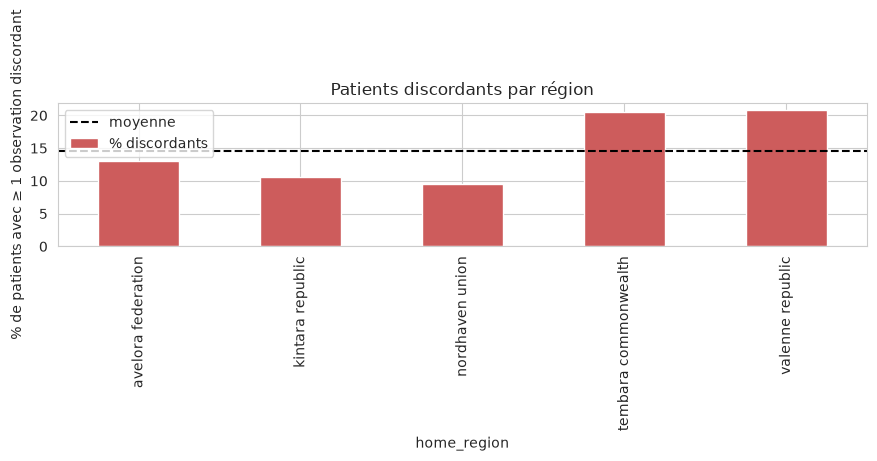

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
reg[['% discordants']].plot.bar(ax=ax, legend=False, color='indianred')
ax.axhline(100 * pat.discordant.mean(), ls='--', color='k', label='moyenne')
ax.set_ylabel('% de patients avec ≥ 1 observation discordant'); ax.set_title('Patients discordants par région'); ax.legend()
plt.tight_layout(); plt.show()

**Lecture**
- Les patients discordants (35) sont répartis dans toutes les régions, et le test du χ² ne montre **pas de dépendance** à la région (p > 0,05). Le phénomène n'est pas géographique.
- Les 8 patients `MRP-42 specialist` viennent chacun de régions différentes (au moins un par région) : ce sont des dirigeants de **plusieurs pays** (chef de gouvernement de Kintara, ministre d'Avelora, gouverneur de Tembara...), soignés dans le même réseau de cliniques. C'est le contraire d'un recrutement local.

### 4. Moran, LISA, régionalisation, Voronoï : non pertinents
- L'**indice de Moran** et les **LISA** mesurent l'autocorrélation spatiale entre voisins : il faut des dizaines d'unités spatiales avec une matrice de voisinage. Ici, 3 établissements (2 à quelques kilomètres, 1 très loin) et 5 régions sans frontières connues : la matrice de poids n'a pas de sens et le test n'aurait aucune puissance.
- La **régionalisation** (regrouper des unités contiguës) et les **diagrammes de Voronoï** (zones d'influence) supposent aussi beaucoup de points. Un Voronoï à 3 sites ne fait que couper le plan en 3, sans information.
- Enfin, les coordonnées sont fictives : une distance entre sites ne correspond à aucun trajet réel.

---
## Partie temporelle
### 1. Construction des séries
Séries d'événements **par mois** (consultations, observations discordantes, procédures `MRP-42`) et **par année** (notes, inscriptions). On se limite à 2017-2025 pour les séries mensuelles : avant 2017, il n'y a que quelques consultations (moins d'une par mois).

,consultations,observations,obs discordant,MRP-42,notes,inscriptions
2014,3,28,0,1,0,1
2015,4,39,0,1,0,3
2016,9,75,0,3,0,5
2017,54,669,7,3,0,48
2018,97,1265,13,4,3,43
2019,134,1839,14,5,3,48
2020,158,2363,14,6,3,46
2021,211,3255,14,6,4,46
2022,156,2986,16,5,3,0
2023,123,2381,12,10,4,0


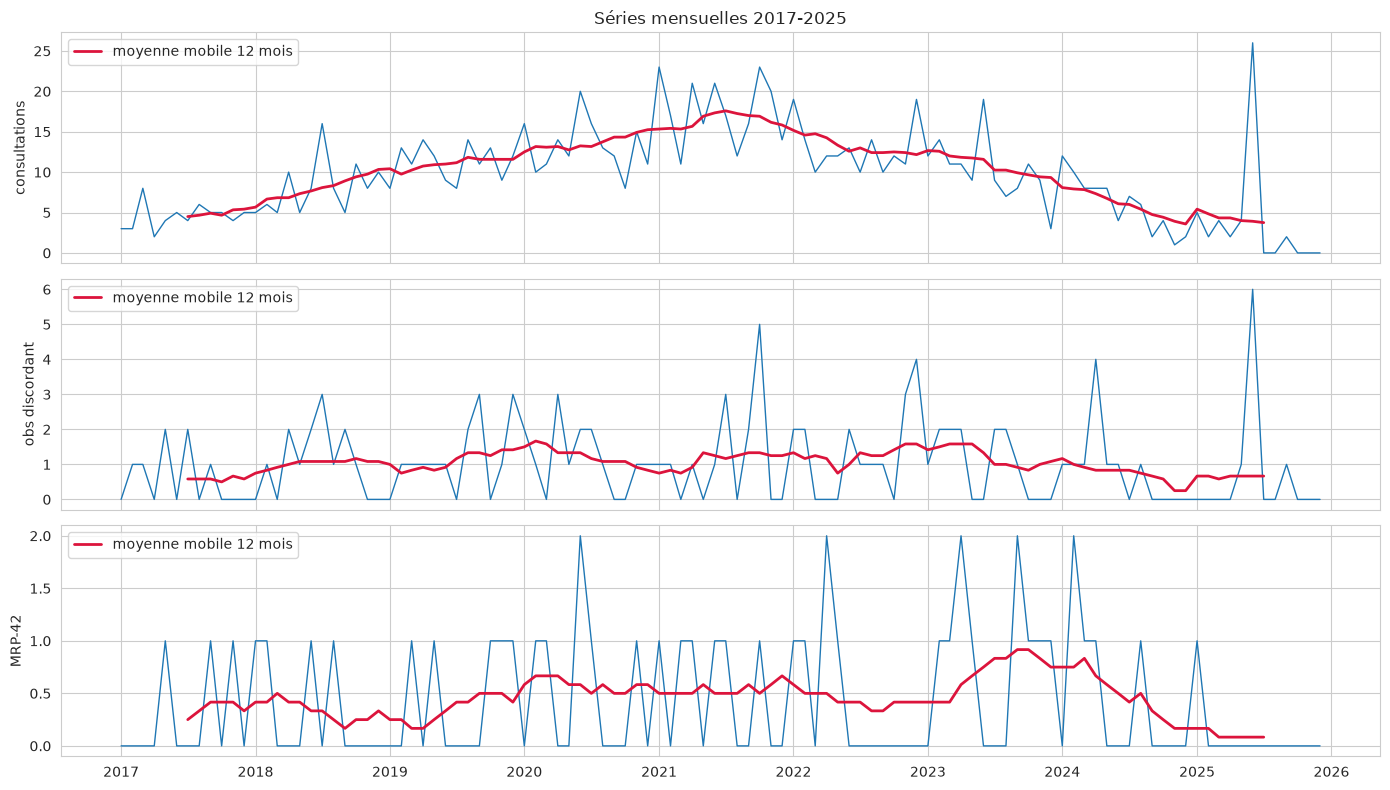

In [7]:
def par_mois(dates, debut='2017-01', fin='2025-12'):
    s = pd.Series(1, index=pd.DatetimeIndex(dates)).resample('MS').sum()
    return s.reindex(pd.date_range(debut, fin, freq='MS'), fill_value=0)

series = pd.DataFrame({
    'consultations': par_mois(enc.encounter_start),
    'obs discordant': par_mois(obs.loc[obs.interpretation_code == 'discordant', 'observation_time']),
    'MRP-42': par_mois(mrp.performed_time),
})
annuel = pd.DataFrame({
    'consultations': enc.groupby(enc.encounter_start.dt.year).size(),
    'observations': obs.groupby(obs.observation_time.dt.year).size(),
    'obs discordant': obs[obs.interpretation_code == 'discordant'].groupby(obs.observation_time.dt.year).size(),
    'MRP-42': mrp.groupby(mrp.performed_time.dt.year).size(),
    'notes': notes.groupby(notes.document_date.dt.year).size(),
    'inscriptions': pat.groupby(pat.registration_date.dt.year).size(),
}).fillna(0).astype(int)
display(annuel)

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, c in zip(axes, series.columns):
    ax.plot(series.index, series[c], lw=1)
    ax.plot(series.index, series[c].rolling(12, center=True).mean(), lw=2, color='crimson', label='moyenne mobile 12 mois')
    ax.set_ylabel(c); ax.legend(loc='upper left')
axes[0].set_title('Séries mensuelles 2017-2025')
plt.tight_layout(); plt.show()

**Lecture : tendance, saisonnalité, cycle, bruit**
- **Tendance** : les consultations montent de 2017 à 2021 puis redescendent jusqu'en 2025 (forme en cloche). Ce n'est pas une épidémie : les patients sont **inscrits entre 2017 et 2021** (table `inscriptions`) puis suivis quelques années. La courbe reflète l'**entrée et la sortie de la cohorte**.
- **Saisonnalité** : rien de visible à l'œil (à vérifier avec l'ACF).
- **Cycle** : aucun cycle long identifiable sur 9 ans de données.
- **Bruit** : fort, avec des mois à 0 et quelques pics.
- La série `MRP-42` est **creuse** (50 événements en 12 ans, souvent 0 par mois) et la série des notes ne compte que 30 points : on ne peut pas y chercher de saisonnalité, on les étudie plutôt en **intervalles entre événements** (section 5).

### 2. L'erreur d'interprétation à éviter
Deux séries qui suivent la même tendance sont **fortement corrélées même sans lien entre elles** (corrélation fallacieuse). Ici, consultations et observations discordantes montent et descendent ensemble.

In [8]:
a = annuel.loc[2017:2025]
print('Corrélation annuelle consultations / discordants (brutes)        :', round(a['consultations'].corr(a['obs discordant']), 2))
print('Corrélation des variations annuelles (séries différenciées)     :', round(a['consultations'].diff().corr(a['obs discordant'].diff()), 2))
taux = (1000 * a['obs discordant'] / a['observations']).round(2)
print('Discordants pour 1000 observations, par année :', taux.to_dict())

Corrélation annuelle consultations / discordants (brutes)        : 0.85
Corrélation des variations annuelles (séries différenciées)     : 0.5
Discordants pour 1000 observations, par année : {2017: 10.46, 2018: 10.28, 2019: 7.61, 2020: 5.92, 2021: 4.3, 2022: 5.36, 2023: 5.04, 2024: 6.49, 2025: 6.34}


La corrélation brute (≈ 0,85) ferait croire que « plus il y a de consultations, plus il y a de cœurs discordants ». Elle vient seulement de la **tendance commune** (taille de la cohorte). Une fois les séries différenciées, elle baisse nettement, et le **taux** de discordance ne suit pas la cloche (il est même plus élevé en 2017-2018). Conclusion : il faut retirer la tendance (ou rapporter à l'effectif) avant de comparer deux séries, et ne pas confondre tendance et effet.

Autre erreur classique, liée : prendre la montée puis la descente des consultations pour un **cycle** ou une saison. C'est une tendance de cohorte, pas un phénomène qui se répète.

### 3. Autocorrélation (ACF)

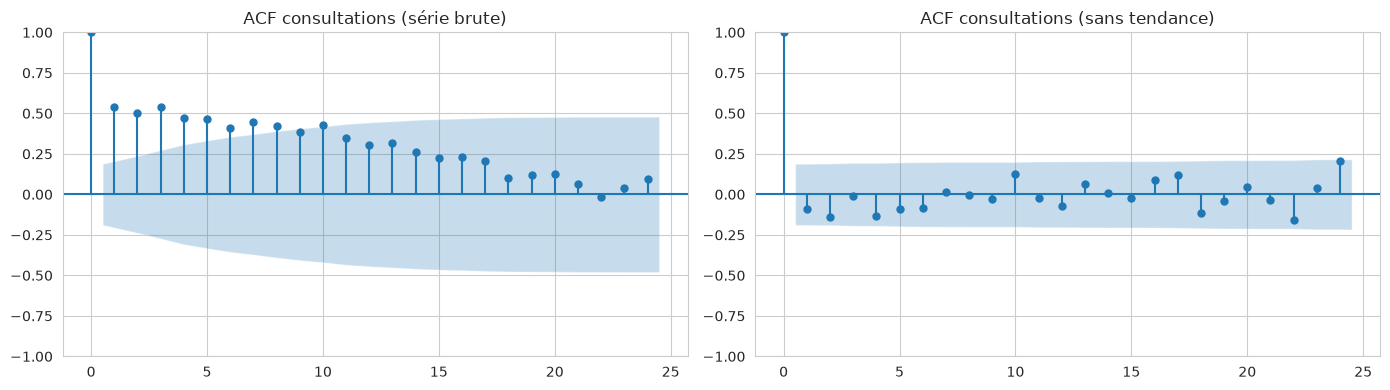

ACF brute, lags 1, 6, 12, 24 : [0.54 0.41 0.3  0.09]
ACF sans tendance, lags 1, 6, 12 : [-0.09 -0.08 -0.07]


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(series['consultations'], lags=24, ax=axes[0], title='ACF consultations (série brute)')
detendu = (series['consultations'] - series['consultations'].rolling(12, center=True, min_periods=6).mean()).dropna()
plot_acf(detendu, lags=24, ax=axes[1], title='ACF consultations (sans tendance)')
plt.tight_layout(); plt.show()
print('ACF brute, lags 1, 6, 12, 24 :', np.round(acf(series['consultations'], nlags=24)[[1, 6, 12, 24]], 2))
print('ACF sans tendance, lags 1, 6, 12 :', np.round(acf(detendu, nlags=12)[[1, 6, 12]], 2))

- **Série brute** : l'ACF décroît lentement (≈ 0,5 au lag 1, encore ≈ 0,3 au lag 12). C'est la signature d'une **tendance**, pas d'une saison : un mois chargé est suivi de mois chargés parce qu'on est au milieu de la cloche.
- **Série sans tendance** : l'ACF tombe dans le bruit dès le lag 1 et **aucun pic au lag 12** : pas de saisonnalité annuelle détectable. Avec 108 mois et ~10 consultations par mois, une saison faible serait de toute façon indétectable ; on le dit plutôt que de la forcer.

### 4. Décomposition (classique et STL)

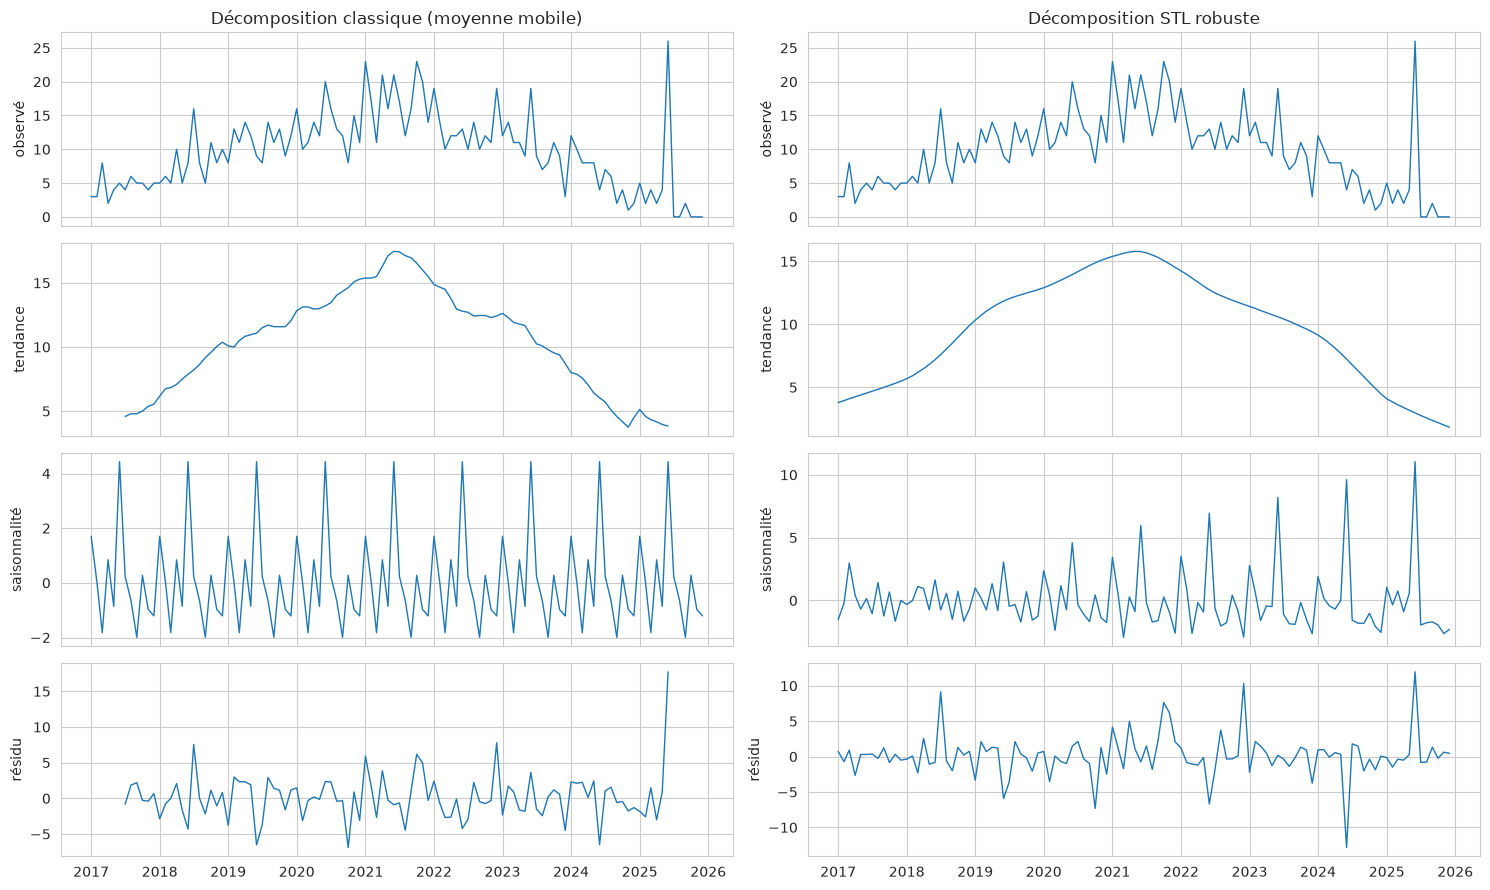

,classique,STL
var tendance,15.22,17.49
var saison,2.86,5.73
var résidu,10.66,8.99


In [10]:
dec = seasonal_decompose(series['consultations'], model='additive', period=12)
stl = STL(series['consultations'], period=12, robust=True).fit()
fig, axes = plt.subplots(4, 2, figsize=(15, 9), sharex=True)
for j, (r, nom) in enumerate([(dec, 'classique (moyenne mobile)'), (stl, 'STL robuste')]):
    for i, (comp, lab) in enumerate([(r.observed, 'observé'), (r.trend, 'tendance'), (r.seasonal, 'saisonnalité'), (r.resid, 'résidu')]):
        axes[i, j].plot(comp.index, comp.values, lw=1)
        axes[i, j].set_ylabel(lab)
    axes[0, j].set_title(f'Décomposition {nom}')
plt.tight_layout(); plt.show()

part = lambda r: pd.Series({'var tendance': np.nanvar(r.trend), 'var saison': np.nanvar(r.seasonal), 'var résidu': np.nanvar(r.resid)})
pd.DataFrame({'classique': part(dec), 'STL': part(stl)}).round(2)

- La **tendance** extraite est la cloche 2017 → 2021 → 2025 dans les deux méthodes.
- La composante **saisonnière** a une amplitude faible et sa variance est petite devant celle du résidu : c'est du bruit que la méthode « range » dans 12 cases, pas une saison. Les deux méthodes imposent une composante saisonnière même quand il n'y en a pas : on ne l'interprète pas.
- Les plus forts résidus (dont **juin 2025**) sont des pics isolés ; STL, robuste, les laisse dans le résidu au lieu de déformer la tendance. On les traite juste après.

### 5. Anomalies par fenêtre glissante
On reprend les méthodes du cours 3 sur une **fenêtre glissante de 12 mois centrée** : pour chaque mois, médiane et MAD de la fenêtre, puis **z-score modifié** `0,6745 × (x − médiane) / MAD` (seuil 3,5). On compare au z-score classique glissant (moyenne, écart-type).

,consultations,mediane fenetre,z modifié,z classique
2018-04-01,10,5.0,4.5,0.9
2018-07-01,16,8.0,5.4,2.4
2025-06-01,26,2.0,10.8,3.1


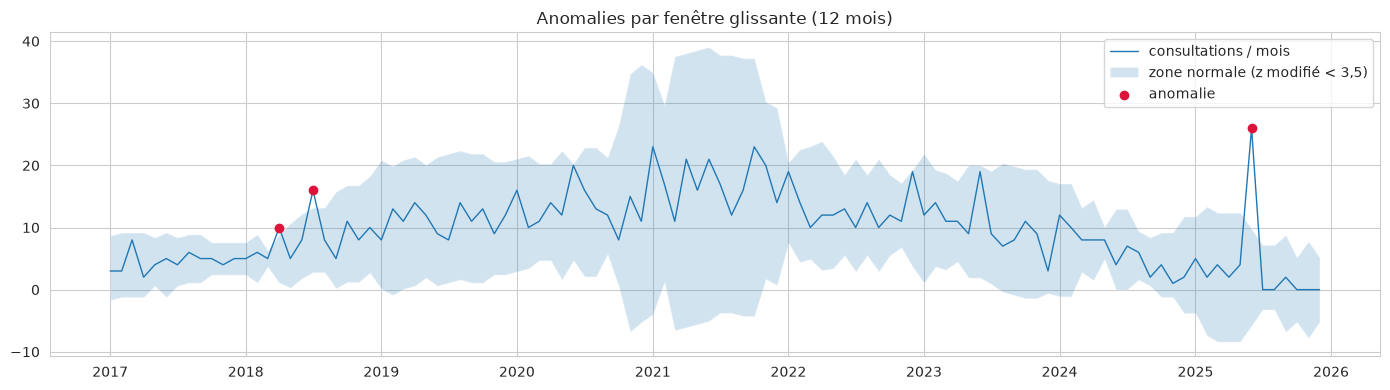

In [11]:
x = series['consultations']
med = x.rolling(12, center=True, min_periods=6).median()
mad = (x - med).abs().rolling(12, center=True, min_periods=6).median()
z_mod = 0.6745 * (x - med) / mad.replace(0, np.nan)
z_cls = (x - x.rolling(12, center=True, min_periods=6).mean()) / x.rolling(12, center=True, min_periods=6).std()
anom = pd.DataFrame({'consultations': x, 'mediane fenetre': med, 'z modifié': z_mod.round(1), 'z classique': z_cls.round(1)})
display(anom[(anom['z modifié'].abs() > 3.5) | (anom['z classique'].abs() > 3)])

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(x.index, x, lw=1, label='consultations / mois')
ax.fill_between(x.index, med - 3.5 * mad / 0.6745, med + 3.5 * mad / 0.6745, alpha=.2, label='zone normale (z modifié < 3,5)')
ax.scatter(x.index[z_mod.abs() > 3.5], x[z_mod.abs() > 3.5], color='crimson', zorder=3, label='anomalie')
ax.legend(); ax.set_title('Anomalies par fenêtre glissante (12 mois)')
plt.tight_layout(); plt.show()

In [12]:
# Que s'est-il passé en juin 2025 ?
juin = enc[enc.encounter_start.dt.to_period('M') == '2025-06']
print(juin.encounter_start.dt.date.value_counts().head(3))
jour = enc[enc.encounter_start.dt.date == pd.Timestamp('2025-06-20').date()].sort_values(['patient_number', 'encounter_start'])
seq = enc.sort_values(['patient_number', 'encounter_start'])
seq['suivi_prevu_avant'] = seq.groupby('patient_number').follow_up_date.shift()
seq['derniere'] = seq.groupby('patient_number').cumcount(ascending=False) == 0
j = seq[seq.encounter_number.isin(jour.encounter_number)]
print(len(j), 'consultations le 2025-06-20,', j.patient_number.nunique(), 'patients différents, sur', j.facility_license_number.nunique(), 'établissements')
print('Heures de début :', j.encounter_start.dt.strftime('%H:%M').value_counts().to_dict())
print('Dernière consultation du patient :', j.derniere.all(), '| suivi prévu à la visite précédente = 2025-06-20 :', (j.suivi_prevu_avant == '2025-06-20').all())
print('Mêmes praticiens à la même heure dans des sites différents :')
print(j.groupby(['attending_license_number', j.encounter_start.dt.strftime('%H:%M')]).facility_license_number.nunique().loc[lambda s: s > 1])

encounter_start
2025-06-20    22
2025-06-21     1
2025-06-11     1
Name: count, dtype: int64
22 consultations le 2025-06-20, 22 patients différents, sur 3 établissements
Heures de début : {'13:15': 17, '12:15': 4, '14:15': 1}
Dernière consultation du patient : True | suivi prévu à la visite précédente = 2025-06-20 : True
Mêmes praticiens à la même heure dans des sites différents :
attending_license_number  encounter_start
LIC-VLN-MED-1002          13:15              2
LIC-VLN-MED-1004          13:15              2
LIC-VLN-RES-1016          13:15              2
LIC-VLN-RES-1044          13:15              2
Name: facility_license_number, dtype: int64


**Lecture**
- Le pic de **juin 2025** est l'anomalie la plus forte (26 consultations contre ~3 attendues). Il vient d'une **seule journée** : 22 consultations le 20 juin 2025, pour 22 patients différents, presque toutes à **13 h 15**, dans les 3 établissements, avec des praticiens présents au même moment dans deux sites différents.
- Pour chacun de ces 22 patients, c'est la **dernière consultation**, et la date de suivi fixée à la visite précédente est **exactement le 2025-06-20**. On en déduit que les dates de suivi ont été **plafonnées** à une date limite lors de la génération, et que la consultation suivante a été placée sur cette date. C'est un **artefact de génération**, pas un événement (même famille que les inscriptions toutes au 1er du mois).
- Le z-score classique glissant ne signale que juin 2025 (z ≈ 3,1) : la moyenne et l'écart-type de la fenêtre sont eux-mêmes tirés par le pic. Le z modifié (médiane, MAD) est plus sensible et signale aussi avril et juillet 2018 (10 et 16 consultations pour une médiane de 5 à 8) : des pics modestes, explicables par le bruit d'une série de ~5-10 événements par mois.

### 6. Séries creuses : intervalles entre administrations de `MRP-42`
La série mensuelle `MRP-42` est trop creuse pour l'ACF. On étudie plutôt le **temps entre deux administrations** chez un même patient.

                       count   mean    std    min    25%    50%    75%     max
authorization_class                                                           
restricted_specialist   22.0  778.0  111.0  714.0  742.0  742.0  743.0  1176.0
Jours de la semaine (specialist) : {'Friday': 16, 'Thursday': 14}
Heure de réalisation : {'research_restricted': ['10:40'], 'restricted_specialist': ['09:05']}


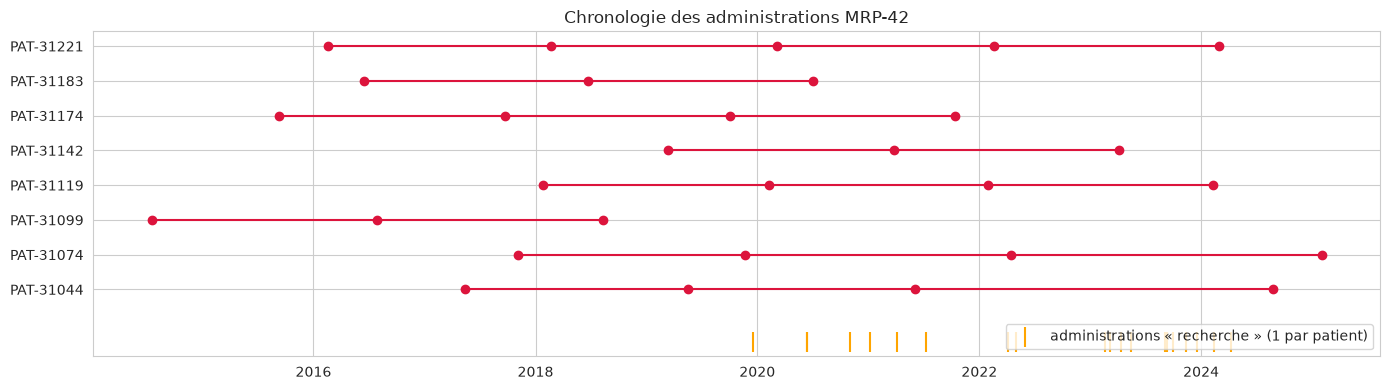

In [13]:
m = mrp.sort_values('performed_time').copy()
m['intervalle_j'] = m.groupby('patient_number').performed_time.diff().dt.days
iv = m.dropna(subset=['intervalle_j'])
print(iv.groupby('authorization_class').intervalle_j.describe().round(0))
print('Jours de la semaine (specialist) :', m[m.authorization_class == 'restricted_specialist'].performed_time.dt.day_name().value_counts().to_dict())
print('Heure de réalisation :', m.groupby('authorization_class').performed_time.apply(lambda s: s.dt.strftime('%H:%M').unique().tolist()).to_dict())

fig, ax = plt.subplots(figsize=(14, 4))
for i, (p_, g) in enumerate(m[m.authorization_class == 'restricted_specialist'].groupby('patient_number')):
    ax.plot(g.performed_time, [i] * len(g), 'o-', color='crimson')
ax.set_yticks(range(len(elite))); ax.set_yticklabels(sorted(elite))
r = m[m.authorization_class == 'research_restricted']
ax.scatter(r.performed_time, [-1.5] * len(r), marker='|', s=200, color='orange', label='administrations « recherche » (1 par patient)')
ax.legend(loc='lower right'); ax.set_title('Chronologie des administrations MRP-42')
plt.tight_layout(); plt.show()

**Lecture**
- Les 8 patients `specialist` reçoivent `MRP-42` **tous les ~742 jours** (médiane, soit 2 ans et 12 jours ; minimum 714). L'intervalle est presque constant : c'est un **protocole périodique**, pas des soins à la demande. Les seuls écarts sont un peu plus longs (jusqu'à ~1 176 jours, une séance « sautée »).
- Les administrations ont lieu uniquement **le jeudi ou le vendredi**, toujours à la même heure (09 h 05 pour `specialist`, 10 h 40 pour `research`) : signature d'un protocole généré, cohérente avec les durées et retards fixes du bloc 3.
- Les administrations `specialist` commencent en **2014** ; les administrations `research` ne commencent qu'en **décembre 2019** et sont concentrées en 2023 : le volet « recherche » arrive **après** des années de traitement de l'élite.
- **Clustering de séries et time warping (DTW)** : non pertinents ici. Ils comparent plusieurs séries alignées et assez longues ; nous avons une seule série dense (consultations) et des séries creuses de 3 à 5 événements par patient.

## À retenir pour le bloc 7
| Observation | Méthode | Nature |
|---|---|---|
| Pic de 22 consultations le 2025-06-20 à 13 h 15, dernières visites, suivi plafonné | Fenêtre glissante + z modifié, retour aux lignes | **Artefact de génération** |
| Courbe en cloche des consultations = entrée/sortie de cohorte ; pas de saisonnalité | Moyenne mobile, ACF, décomposition classique et STL | Pas un indice |
| Corrélation consultations / discordants ≈ 0,85 due à la tendance | Différenciation, taux | Piège évité |
| `MRP-42 specialist` tous les ~742 jours depuis 2014 ; volet recherche à partir de fin 2019 | Intervalles entre événements | **Indice** : protocole périodique pour l'élite, essai plus tardif |
| `MRP-42 specialist` uniquement dans les 2 cliniques Asterion ; patients de 5 régions différentes | Agrégation par site et par région | **Indice** : réseau transnational |
| Discordance indépendante de la région et du site | χ², taux par site | Pas d'effet géographique ni d'appareil |